# Pretraining

In [5]:
%load_ext autoreload
%autoreload 2

In [1]:
# Save Model
import torch
import time
import random
import sys
from data.swarmset import ContinuingDataset, SwarmDataset
from src.networks.embedding import NoveltyEmbedding
from src.networks.archive import DataAggregationArchive
from src.networks.ensemble import Ensemble
import numpy as np
from scipy import ndimage
import cv2
from torchvision.transforms import RandomResizedCrop, RandomHorizontalFlip, RandomVerticalFlip

GLOBAL_SEED = 1
np.random.seed(GLOBAL_SEED)
random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)

PRETRAINING = True
TOTAL_EPOCHS = 150
target = 0.0001
loss = 50
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(device)
ensemble = Ensemble(size=1, output_size=5, lr=3e-2, weight_decay=1e-6, new_model=True, manual_schedulers=False, dynamic_lr=False, init="Random", warmup=5, margin=1)
# ensemble.load_ensemble("01-30-23-2S-Heur-Pre-B")
sampled_dataset = SwarmDataset("data/HeRo-Pro", rank=0)

def resizeInput(X, w=200):
    frame = X.astype(np.uint8)
    resized = cv2.resize(frame, dsize=(w, w), interpolation=cv2.INTER_AREA)
    return resized

def translate(img, offset=(10, 10)):
    h, w = img.shape
    xoff, yoff = offset
    if xoff < 0: xpadding = (0, -xoff)
    else: xpadding = (xoff, 0)
    if yoff < 0: ypadding = (0, -yoff)
    else: ypadding = (yoff, 0)
    img = np.pad(img, (xpadding, ypadding))

    if xoff >= 0 and yoff >= 0:
        return img[:w, :w]
    elif xoff < 0 and yoff >= 0:
        return img[-w:, :w]
    elif xoff >= 0 and yoff < 0:
        return img[:w, -w:]
    return img[-w:, -w:]

def zoom_at(img, zoom, coord=None):
    # Adapted from https://stackoverflow.com/questions/69050464/zoom-into-image-with-opencv
    h, w = [ zoom * i for i in img.shape ]
    if coord is None: cx, cy = w/2, h/2
    else: cx, cy = [ zoom*c for c in coord ]
    img = cv2.resize( img, (0, 0), fx=zoom, fy=zoom)
    img = img[ int(round(cy - h/zoom * .5)) : int(round(cy + h/zoom * .5)),
               int(round(cx - w/zoom * .5)) : int(round(cx + w/zoom * .5))]
    return img

def get_color_distortion(X, s=3.0):
    X = X + s * np.random.randn(X.shape[0], X.shape[1])
    return X

def getRandomTransformation(image, k=2):
    transformation_choices = ["Rotation", "Blur", "Zoom", "Translate", "Distort", "ResizedCrop"]
    # weights = [0.4, 0.3, 0.0, 0.2]
    # weights = [1.0, 0.0, 0.0, 0.0]
    # choices = random.choices(transformation_choices, weights, k=k)
    choices = ["ResizedCrop", "Rotation"]
    if "ResizedCrop" in choices:
        tmp = torch.tensor(image).unsqueeze(0)
        flipper = RandomHorizontalFlip(0.5)
        cropper = RandomResizedCrop(size=(50,50), scale=(0.6, 1.0), ratio=(1.0, 1.0))
        image = flipper(cropper(tmp))
        image = image.squeeze(0).numpy()
    if "Rotation" in choices:
        theta = random.choice([90, 180, 270])
        image = ndimage.rotate(image, theta)
    if "Blur" in choices:
        blur = random.choice([0.5, 1.0, 1.5])
        image = ndimage.gaussian_filter(image, sigma=blur)
    if "Zoom" in choices:
        # zoom = random.choice([1.06, 1.12, 1.18])
        padding = random.choice([10])
        padded = np.pad(image, padding, mode='constant')
        image = resizeInput(padded, 50)
    if "Translate" in choices:
        offsets = [i for i in range(-10, 10, 2)]
        offset = (random.choice(offsets), random.choice(offsets))
        # offset = (2, 2)
        image = translate(image, offset)
    if "Distort" in choices:
        strength = random.choice([3.0, 5.0, 10.0])
        image = get_color_distortion(image, s=strength)
    if "Flip" in choices:
        tmp = torch.tensor(image).unsqueeze(0)
        flipper = RandomHorizontalFlip(1.0)
        image = flipper(tmp)
        image = image.squeeze(0).numpy()
    return image

def pretraining(data, ensemble, data_cutoff=None, data_size=500):
    if data_cutoff is None:
        data_cutoff = len(data) - 1
    # np.random.seed(0)
    samples = np.random.random_integers(0, data_cutoff, (data_size, 2))
    total_loss = np.array([0.0 for i in range(len(ensemble.ensemble))])

    BATCH_SIZE = 2048  # TODO: Massive Batch Size?
    total_updates = 0
    total_batches = data_size // BATCH_SIZE

    # Batch the data
    for i in range(0, len(samples), BATCH_SIZE):
        # AUGMENT_SIZE = 1
        # if i + (BATCH_SIZE * AUGMENT_SIZE) >= len(pull_set):
        #     continue

        print(f"Unsupervised Training.. {(total_updates * 100) / total_batches}")

        temp_losses = np.array([0.0 for _ in ensemble.ensemble])

        anchors = np.array([data[samples[i + j][0]][0] for j in range(BATCH_SIZE)])
        positives = np.array([getRandomTransformation(data[samples[i + j][0]][0]) for j in range(BATCH_SIZE)])
        negatives = np.array([data[samples[i + j][1]][0] for j in range(BATCH_SIZE)])

        anchors = np.expand_dims(anchors, axis=1)
        positives = np.expand_dims(positives, axis=1)
        negatives = np.expand_dims(negatives, axis=1)

        losses = ensemble.train_batch(anchors, positives, negatives)
        temp_losses += losses

        total_loss += temp_losses
        total_updates += 1

    return total_loss, max(total_updates, 1)

t_1 = time.time()

if PRETRAINING:
    epochs = 0
    loss_history = []
    while epochs < TOTAL_EPOCHS:
        losses, total_updates = pretraining(sampled_dataset, ensemble, data_cutoff=499, data_size=(4096 * 6))
        average_loss = losses / total_updates
        locale_loss = sum(average_loss) / len(average_loss)
        loss_history.append(locale_loss)
        loss = (sum(loss_history[-3:]) / 3) if len(loss_history) > 3 else 50
        print(f"Losses: {average_loss}")
        print(f"Epoch {epochs}, loss: {locale_loss}, windowed_loss: {loss}")
        # print(f"LRs: {ensemble.get_lr()}")
        epochs += 1
        ensemble.step_schedulers(losses)

print(f"Total Pre-training Time: {time.time() - t_1}")
ensemble.save_ensemble(f"{int(time.time())}")

pygame 2.1.2 (SDL 2.0.18, Python 3.10.14)
Hello from the pygame community. https://www.pygame.org/contribute.html
mps
Initialized Network with  1658117 parameters
Unsupervised Training.. 0.0


/var/folders/ln/qnbn1cnd243g_w8qr5qzfhp00000gn/T/ipykernel_32205/2804336096.py:108: DeprecationWarning: This function is deprecated. Please call randint(0, 499 + 1) instead
  samples = np.random.random_integers(0, data_cutoff, (data_size, 2))


FileNotFoundError: [Errno 2] No such file or directory: 'data/HeRo-Pro/37/behavior.png'

In [2]:
ensemble.save_ensemble(f"{int(time.time())}")

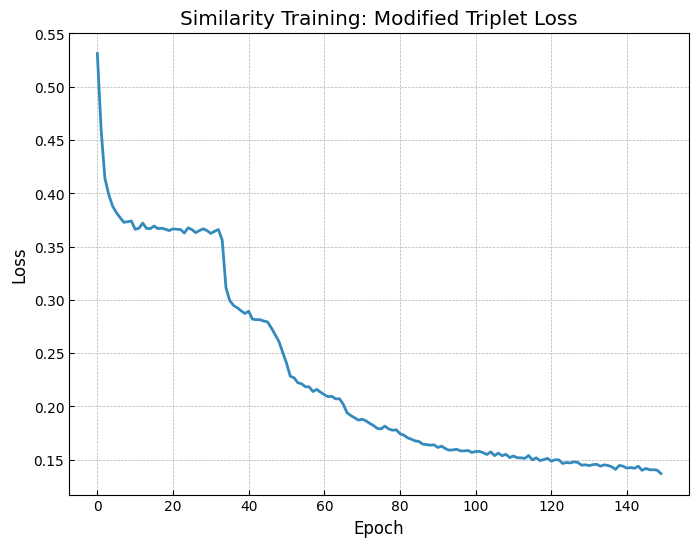

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use("bmh")
plt.rcParams.update({"figure.figsize" : (8, 6),
                     "axes.facecolor" : "white",
                     "axes.edgecolor":  "black"})
plt.plot(loss_history)
# plt.ylim(0, 1)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Similarity Training: Modified Triplet Loss")
plt.show()

# MISC Cells Below

In [4]:
from data.swarmset import ContinuingDataset, SwarmDataset
from src.networks.ensemble import Ensemble
import numpy as np
import torch
print("Hi?")

device = "cpu"

ENSEMBLE_PATH = "~/Desktop/DevProjects/SwarmBehaviorDiscovery/src/z-experiments/Sum24-notebooks/checkpoints/ensembles/network_64"
ensemble = Ensemble(size=1, output_size=5, lr=3e-2, weight_decay=1e-6, new_model=True, manual_schedulers=False, dynamic_lr=False, init="Random", warmup=5, margin=1)
if ENSEMBLE_PATH is not None:
    ensemble.load_ensemble(ENSEMBLE_PATH, full=True)
ensemble.eval_mode()
ensemble.ensemble[0].to(device)

embeddings = []
classes = []
# for i in range(len(data)):
sampled_dataset = SwarmDataset("data/single", rank=0)
for i in range(500):
    image = sampled_dataset[i][0]
    image = np.expand_dims(image, axis=0)
    print(image.shape)
    embed = ensemble.ensemble[0].numpy_single_pass(image)
    embed = embed.detach().cpu().squeeze(dim=0).numpy()
    embeddings.append(embed)
    print(embed)

Hi?
Initialized Network with  1658117 parameters
(1, 50, 50)
[-2.4344881e+09  1.1165869e+09 -1.0240566e+09  5.1136710e+08
 -2.1876954e+08]
(1, 50, 50)
[-1.1932541e+09  2.8266801e+09 -1.1449563e+09  6.6305165e+08
 -6.0259789e+08]
(1, 50, 50)
[-8.6073702e+08  2.1696143e+09  3.0764077e+08 -5.0682010e+08
  4.8227773e+08]
(1, 50, 50)
[-1.5353448e+09  1.1560154e+09  3.9287917e+08 -1.4681546e+09
 -5.0814490e+08]
(1, 50, 50)
[-2.0596212e+09  1.5798318e+09  8.3692083e+08  7.5073030e+08
 -1.2863305e+09]
(1, 50, 50)
[-1.9518404e+09  1.8468644e+09  3.1826938e+08 -1.4723251e+09
 -5.9070669e+08]
(1, 50, 50)
[-1.4712951e+09  3.0592374e+09 -2.0977011e+08 -1.9157302e+08
 -6.0189440e+07]
(1, 50, 50)
[-2.3300805e+09  6.9851994e+08  1.7619814e+08  8.0400640e+08
 -7.1779936e+08]
(1, 50, 50)
[-1.6215871e+09  9.7798675e+08 -5.6327386e+08  1.1685484e+09
 -8.5697498e+08]
(1, 50, 50)
[-1.8739404e+09  1.2931053e+09  2.7151898e+08 -1.5823654e+09
 -8.2249107e+08]
(1, 50, 50)
[-3.5453949e+08  2.0776687e+09 -3.53110

[W NNPACK.cpp:53] Could not initialize NNPACK! Reason: Unsupported hardware.


[-1.1094534e+09  2.6769933e+09  1.1986662e+08 -3.1614672e+08
  3.6609798e+08]
(1, 50, 50)
[-1.9029117e+09  1.2015537e+09  6.2740736e+07  9.7692224e+08
 -1.0731003e+09]
(1, 50, 50)
[-1.7107323e+08  7.0126592e+07 -1.0041670e+08 -1.1958173e+08
 -2.0155603e+08]
(1, 50, 50)
[-2.0335766e+09  1.8484332e+09  8.3549824e+08  7.6660422e+08
 -1.4796024e+09]
(1, 50, 50)
[-2.2080737e+09  1.0411895e+09  7.0418150e+08  7.8622202e+08
 -9.8339443e+08]
(1, 50, 50)
[-5.3832838e+08  1.5807593e+09  3.4067366e+08 -4.7490742e+08
  4.8153123e+08]
(1, 50, 50)
[-6.0588902e+08  4.7199571e+08 -6.4615821e+08  8.9858810e+08
 -6.8617075e+08]
(1, 50, 50)
[-7.2576858e+08  2.3706166e+09  9.4724736e+07 -1.5122637e+08
  5.1793011e+08]
(1, 50, 50)
[-1.6721418e+09  3.0987653e+09  1.4104320e+08 -5.9829690e+08
  9.1475904e+07]
(1, 50, 50)
[-1.9237240e+09  1.7770734e+09  7.6443955e+08  7.6026886e+08
 -1.4265796e+09]
(1, 50, 50)
[-2.4363945e+09  1.6814021e+09 -1.3120494e+09  1.1545002e+08
 -1.3892122e+08]
(1, 50, 50)
[-4.662253

In [7]:
from sklearn.manifold import TSNE
import numpy as np
reduced = TSNE(
    n_components=3,
    learning_rate="auto",
    init="pca",
    perplexity=50,
    early_exaggeration=8
).fit_transform(np.array(embeddings))

~/anaconda3/envs/BehaviorDiscovery/lib/python3.10/site-packages/sklearn/manifold/_t_sne.py:996: FutureWarning: The PCA initialization in TSNE will change to have the standard deviation of PC1 equal to 1e-4 in 1.2. This will ensure better convergence.
  warnings.warn(


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


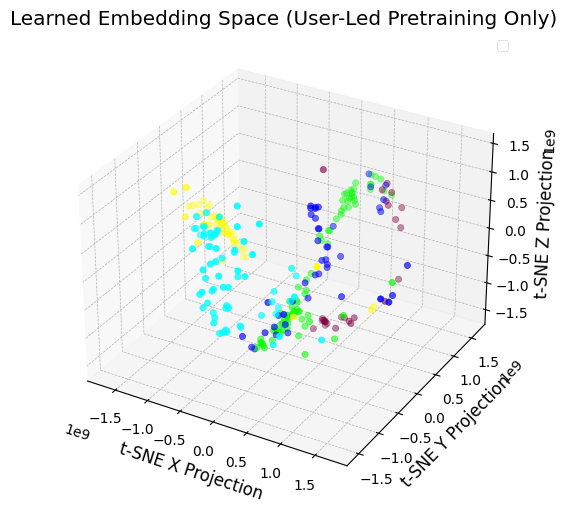

In [8]:
import matplotlib.pyplot as plt
import os

color_classes = {
    -1: [0.33, 0.33, 0.33],
    0: [1, 0, 0], # Red
    1: [0, 1, 0], # Green
    2: [0, 0, 1], # Blue
    3: [0, 1, 1], # Cyan
    4: [1, 1, 0], # Yellow
    5: [0.5, 0, 0.25], # Pink
    6: [0, 0, 0]
}

label_classes = {
    -1: "Unlabeled",
    0: "Random",
    1: "Cyclic Pursuit",
    2: "Milling",
    3: "Aggregation",
    4: "Dispersal",
    5: "Wall Following",
    6: "Special"
}

def CSVLineToVec(line):
    line_list = line.strip().replace("\n", "").split(",")
    float_list = []
    for i in line_list:
        float_list.append(float(i))
    float_list = np.array(float_list)
    return float_list

classes = [-1 for i in range(500)]
with open("~/Desktop/DevProjects/SwarmBehaviorDiscovery/src/z-experiments/Sum24-notebooks/data/oracle_labels/single.csv", "r") as f:
    lines = f.readlines()
    for line in lines:
        triplet = CSVLineToVec(line)
        classes[int(triplet[0])] = int(triplet[1])

lim = len(reduced)
RANDOM = 0
x = [reduced[i][0] for i in range(lim) if classes[i] != RANDOM]
y = [reduced[i][1] for i in range(lim) if classes[i] != RANDOM]
z = [reduced[i][2] for i in range(lim) if classes[i] != RANDOM]
colors = [color_classes[classes[i]] for i in range(lim)  if classes[i] != RANDOM]
# labels = [label_classes[classes[i]] for i in range(lim)  if classes[i] != RANDOM]
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(x, y, z, c=colors)
# ax.set_xlim(-200, 175)
# ax.set_ylim(-50, 400)
# ax.set_zlim(-2, 2)
ax.set_title("Learned Embedding Space (User-Led Pretraining Only)")
ax.set_xlabel("t-SNE X Projection")
ax.set_ylabel("t-SNE Y Projection")
ax.set_zlabel("t-SNE Z Projection")
ax.legend()

plt.show()